# The setting and the throw against power: Bond energy, its closed-form oracle and the trade-off map

**Question:** Does the engine's power equal the closed-form Bond energy times the throughput, and which lever, the setting or the throw, gives the most tonnes for a required product size?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state Bond's third theory of comminution, and compute the energy of a reduction from F80 to P80 with an oracle that shares no code with the engine;
- check the engine's power against that oracle over a grid of settings and throws;
- read the specific energy in kWh per tonne as the cost of a unit of size reduction;
- map product size against throughput for the two levers, and find the best combination for a required P80.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The oracle's two Bond functions are imported next to the engine; the notebook never defines its own.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.capacity import throughput
from pipeline.oracles import bond_energy_kwh_t, bond_power_kw
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The reference case S01 again, as the base of the sweeps. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads the operating point.

In [2]:
# Read the S01 operating point
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
print(op.machine, op.css_mm, op.throw_mm, op.speed_rpm, "| Wi =", op.ore_wi, "kWh/t")

cone-sec 32.0 30.0 360.0 | Wi = 14.0 kWh/t


## Method

**Step 1, Bond's law.** Bond (1952; https://onemine.org/documents/the-third-theory-of-comminution) stated that the energy to reduce a feed of size $F_{80}$ to a product of size $P_{80}$ is

$$W = 10\,W_i\left(\frac{1}{\sqrt{P_{80}}} - \frac{1}{\sqrt{F_{80}}}\right)\ [\mathrm{kWh/t}], \qquad P_{\mathrm{kW}} = W\,Q$$

with the sizes in micrometres and $W_i$ the Bond work index, the energy to reduce the ore from infinite size to $P_{80} = 100\ \mu\mathrm{m}$. The engine uses it for its power draw. The oracle `bond_energy_kwh_t` of `data-pipeline/pipeline/oracles.py` implements the same law from the paper's statement, with no code shared with the engine, so a disagreement would be a finding about one of the two. The cell runs the engine on S01 and compares its power with the oracle's, fed with the engine's own F80, P80 and throughput.

In [3]:
# Engine power on S01 against the oracle's Bond power from the engine's own F80, P80 and throughput
base = evaluate(op)
energy = bond_energy_kwh_t(base.f80, base.p80, op.ore_wi)
power = bond_power_kw(base.throughput_tph, base.f80, base.p80, op.ore_wi)
print(f"F80 = {base.f80:.3f} mm, P80 = {base.p80:.3f} mm, Wi = {op.ore_wi} kWh/t, Q = {base.throughput_tph:.2f} t/h")
print("oracle energy [kWh/t]:", round(energy, 4), "| oracle power [kW]:", round(power, 4),
      "| engine power [kW]:", round(base.power_kw, 4))

F80 = 126.033 mm, P80 = 27.698 mm, Wi = 14.0 kWh/t, Q = 643.16 t/h
oracle energy [kWh/t]: 0.4469 | oracle power [kW]: 287.3985 | engine power [kW]: 287.3985


The two agree on this point to the digits printed. One point can agree by coincidence, so the next cell compares the engine and the oracle over a grid of 7 settings and 5 throws, 35 operating points, and reports the largest relative difference. The engine's reference energy per nip, $E_{cs}$, is a different quantity from the Bond energy $W$: the first drives the breakage function, the second prices the reduction that resulted.

In [4]:
# Compare the engine's power with the oracle's over a grid of settings and throws
settings = op.css_mm * np.array([0.5, 0.65, 0.8, 1.0, 1.2, 1.4, 1.6])
throws = np.array([16.0, 23.0, 30.0, 37.0, 44.0])
grid = {}
for css in settings:
    for th in throws:
        grid[(css, th)] = evaluate(replace(op, css_mm=float(css), throw_mm=float(th)))
gap = 0.0
for r in grid.values():
    oracle_kw = bond_power_kw(r.throughput_tph, r.f80, r.p80, op.ore_wi)
    gap = max(gap, abs(r.power_kw - oracle_kw) / r.power_kw)
print("points compared:", len(grid), "| largest relative difference engine to oracle:", f"{gap:.2e}")

points compared: 35 | largest relative difference engine to oracle: 0.00e+00


**Step 2, what the law prices.** The Bond energy depends on the sizes only through $1/\sqrt{P_{80}} - 1/\sqrt{F_{80}}$, so for a fixed feed each halving of P80 costs more energy than the previous one. The figure draws $W$ from the oracle against P80 for three feed sizes and marks S01's point. It is a picture of the law, not of the engine, and it says how steep the energy bill gets as the product is asked to be finer.

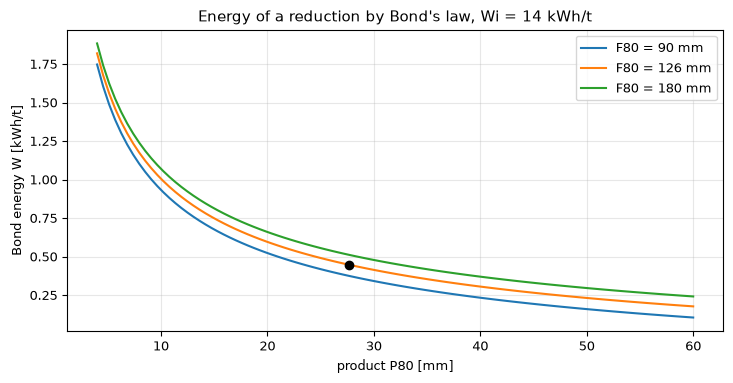

In [5]:
# Plot the oracle's Bond energy against P80 for three feed sizes and mark S01
p80 = np.linspace(4, 60, 100)
fig, ax = plt.subplots()
for f80 in (90.0, base.f80, 180.0):
    ax.plot(p80, [bond_energy_kwh_t(f80, v, op.ore_wi) for v in p80], label=f"F80 = {f80:.0f} mm")
ax.plot([base.p80], [energy], "ko")
ax.set_xlabel("product P80 [mm]")
ax.set_ylabel("Bond energy W [kWh/t]")
ax.set_title("Energy of a reduction by Bond's law, Wi = 14 kWh/t")
ax.legend()
fig.tight_layout()
plt.show()

Every curve falls steeply for fine products and flattens for coarse ones, and a coarser feed raises all of them. S01's black dot sits on the F80 = 126 curve at 0.45 kWh/t, a modest value because a secondary crusher reduces by a factor of about 4.5 only. The figure does not show whether Bond's law, which was calibrated on grinding, is a good descriptor of coarse crushing; the repository's power-model card records the contrary finding on the real surveys, which topic 05 and topic 06 take up.

Before drawing the map, the capacity law can be read alone: at S01's setting and speed it gives the throughput of every throw without running the engine, and the grid's engine runs should reproduce it, since the engine calls the same law. The cell prints both side by side for the five throws.

In [6]:
# Capacity of each throw from the closed-form law alone, next to the engine's run on the grid
for th in throws:
    law = throughput(op.machine, op.css_mm, float(th), op.speed_rpm)
    run = grid[(settings[3], th)]
    print(f"throw {th:4.1f} mm: law {law:6.1f} t/h | engine {run.throughput_tph:6.1f} t/h | P80 {run.p80:5.2f} mm")
first, last = grid[(settings[3], throws[0])], grid[(settings[3], throws[-1])]
gain, coarsening = last.throughput_tph - first.throughput_tph, last.p80 - first.p80
print(f"throw {throws[0]:.0f} to {throws[-1]:.0f} mm at S01's setting: +{gain:.0f} t/h for +{coarsening:.1f} mm of P80")

throw 16.0 mm: law  547.4 t/h | engine  547.4 t/h | P80 25.01 mm
throw 23.0 mm: law  595.3 t/h | engine  595.3 t/h | P80 26.29 mm
throw 30.0 mm: law  643.2 t/h | engine  643.2 t/h | P80 27.70 mm
throw 37.0 mm: law  691.1 t/h | engine  691.1 t/h | P80 29.08 mm
throw 44.0 mm: law  738.9 t/h | engine  738.9 t/h | P80 30.45 mm
throw 16 to 44 mm at S01's setting: +192 t/h for +5.4 mm of P80


**Step 3, the two levers.** The setting sets the discharge opening and the size selected, the throw opens the mean gap and, through K2, lets larger particles escape. Both raise throughput and coarsen the product, so the question is which does it more cheaply. The cell traces two families of curves on the 35-point grid: for each throw, the curve of P80 against throughput as the setting varies, and for each setting the curve as the throw varies.

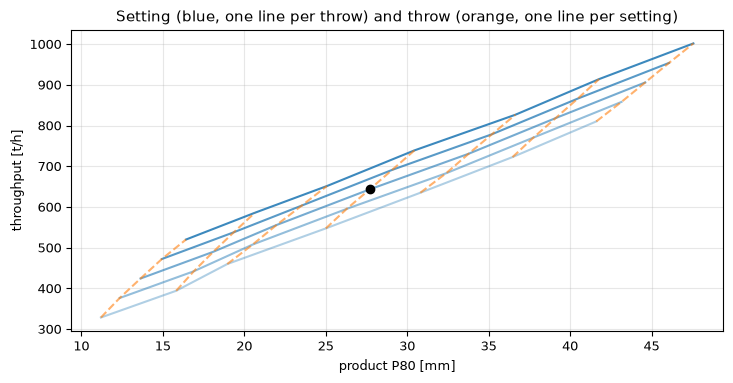

In [7]:
# Map throughput against P80: one line per throw (setting varies) and one per setting (throw varies)
fig, ax = plt.subplots()
for k, th in enumerate(throws):
    ax.plot([grid[(css, th)].p80 for css in settings], [grid[(css, th)].throughput_tph for css in settings],
            "-", color="tab:blue", alpha=0.35 + 0.13 * k)
for css in settings:
    ax.plot([grid[(css, th)].p80 for th in throws], [grid[(css, th)].throughput_tph for th in throws],
            "--", color="tab:orange", alpha=0.6)
ax.plot([base.p80], [base.throughput_tph], "ko")
ax.set_xlabel("product P80 [mm]")
ax.set_ylabel("throughput [t/h]")
ax.set_title("Setting (blue, one line per throw) and throw (orange, one line per setting)")
fig.tight_layout()
plt.show()

The blue lines, one per throw, are the shallower ones: along them the setting raises P80 by a lot for each extra tonne per hour. The orange lines, one per setting, are shallower in P80 and steeper in tonnes: along them the throw raises the throughput by about 190 t/h for only about 5 mm of P80. So the throw is the cheaper lever for capacity, in terms of the coarsening of the product, and the setting is the lever for the size itself. The figure does not include the power, which the last step brings in, and it is a model statement: a real machine limits the throw by its mechanical design.

**Step 4, the best combination for a required size.** Given a P80 requirement, the plant wants the most tonnes at the least energy. The cell filters the 35 operating points of the grid by P80 not above 25 mm, ranks them by throughput, and prints the best and its specific energy, the Bond energy of the oracle for its own F80 and P80, next to the S01 point.

In [8]:
# Rank the grid points with P80 up to 25 mm by throughput and print the best with its specific energy
feasible = sorted((r for r in grid.values() if r.p80 <= 25.0), key=lambda r: -r.throughput_tph)
print("points with P80 <= 25 mm:", len(feasible), "of", len(grid))
for r in feasible[:3]:
    w = bond_energy_kwh_t(r.f80, r.p80, op.ore_wi)
    print(f"CSS {r.op.css_mm:5.1f} mm, throw {r.op.throw_mm:4.1f} mm: {r.throughput_tph:6.1f} t/h,",
          f"P80 {r.p80:5.2f} mm, {w:.3f} kWh/t")
w_s01 = bond_energy_kwh_t(base.f80, base.p80, op.ore_wi)
print(f"S01: CSS {op.css_mm} mm, throw {op.throw_mm} mm: {base.throughput_tph:.1f} t/h,",
      f"P80 {base.p80:.2f} mm, {w_s01:.3f} kWh/t")
best = feasible[0]
tonnage = (best.throughput_tph / base.throughput_tph - 1) * 100
energy_change = (bond_energy_kwh_t(best.f80, best.p80, op.ore_wi) / w_s01 - 1) * 100
same_throw = [r for r in feasible if r.op.css_mm == best.op.css_mm and r.op.throw_mm == op.throw_mm][0]
extra = best.throughput_tph - same_throw.throughput_tph
print(f"best against S01: tonnage {tonnage:+.1f} %, specific energy {energy_change:+.1f} %")
print(f"best against the same setting with S01's throw: {extra:.1f} t/h more")

points with P80 <= 25 mm: 14 of 35
CSS  25.6 mm, throw 37.0 mm:  603.5 t/h, P80 23.53 mm, 0.518 kWh/t
CSS  20.8 mm, throw 44.0 mm:  585.7 t/h, P80 20.65 mm, 0.580 kWh/t
CSS  25.6 mm, throw 30.0 mm:  555.6 t/h, P80 21.98 mm, 0.550 kWh/t
S01: CSS 32.0 mm, throw 30.0 mm: 643.2 t/h, P80 27.70 mm, 0.447 kWh/t
best against S01: tonnage -6.2 %, specific energy +16.0 %
best against the same setting with S01's throw: 47.9 t/h more


## Results

**Answer:** the engine's power equals the closed-form Bond power: at S01 both are 287.3985 kW for F80 = 126.033 mm, P80 = 27.698 mm and 643.16 t/h (0.4469 kWh/t), and over 35 operating points the largest relative difference is 0.00e+00: the two are identical to the last bit, as expected from the same closed form in double precision. For the levers, the throw buys capacity cheaply in terms of product size, 192 t/h for 5.4 mm of P80 along the constant-setting line of S01, while the setting buys size. Under a 25 mm P80 requirement 14 of the 35 points qualify, and the best is a tighter setting with more throw, CSS 25.6 mm and throw 37 mm: 603.5 t/h at P80 23.53 mm and 0.518 kWh/t, against S01's 643.2 t/h at 27.70 mm and 0.447 kWh/t, so the finer product costs 6.2 percent of the tonnage and 16.0 percent more energy per tonne. At the same setting with S01's own throw the tonnage would be 555.6 t/h, 47.9 t/h less.

The first figure shows the steepness of the Bond energy for fine products, the second the two families of lines. A validator would conclude that the power in this engine is a faithful implementation of Bond's law and nothing more: its agreement with the oracle tests the code, not the law. What this notebook does not show is that Bond's law predicts the power of a real crusher; the power parity against the HP500 measurements, in topic 05 and topic 06, is where that is tested, with a negative result the repository reports.

## Summary

Bond's law is the only place where the engine turns size reduction into power, and an independent closed form reproduces it to rounding. The two operator levers act differently: the throw opens the machine and the setting sets the size, and a required P80 picks a combination between them. The next topic leaves the synthetic cases and runs the calibrated engine on the ten real surveys of an industrial cone.

## References

- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Evertsson, C. M. (2000), Cone crusher performance, doctoral thesis, Chalmers University of Technology. https://research.chalmers.se/en/publication/759
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193